In [37]:
import scipy.io as sio

# MATLAB file
mat_data = sio.loadmat('CMP_Data.mat')

print(mat_data.keys())

# Extracting Data1
data = mat_data['Data1']

# dataset size
print("Dataset shape:", data.shape)

dict_keys(['__header__', '__version__', '__globals__', 'Data1', 'Data2'])
Dataset shape: (364, 26)


In [38]:
import numpy as np


column_names = [
    'MACHINE_ID',
    'MACHINE_DATA',
    'TIMESTAMP',
    'WAFER_ID',
    'STAGE',
    'CHAMBER',
    'USAGE_OF_BACKING_FILM',
    'USAGE_OF_DRESSER',
    'USAGE_OF_POLISHING_TABLE',
    'USAGE_OF_DRESSER_TABLE',
    'PRESSURIZED_CHAMBER_PRESSURE',
    'MAIN_OUTER_AIR_BAG_PRESSURE',
    'CENTER_AIR_BAG_PRESSURE',
    'RETAINER_RING_PRESSURE',
    'RIPPLE_AIR_BAG_PRESSURE',
    'USAGE_OF_MEMBRANE',
    'USAGE_OF_PRESSURIZED_SHEET',
    'SLURRY_FLOW_LINE_A',
    'SLURRY_FLOW_LINE_B',
    'SLURRY_FLOW_LINE_C',
    'WAFER_ROTATION',
    'STAGE_ROTATION',
    'HEAD_ROTATION',
    'DRESSING_WATER_STATUS',
    'EDGE_AIR_BAG_PRESSURE',
    'MRR'
]


print(f"{'Column':<4} {'Name':<32} {'Non-Null':<10} {'Missing %':<12} {'Unique':<8} {'Zero Variance'}")

# Analyzing each column
for i in range(data.shape[1]):

    column = data[:, i]

    # Number of values that are NOT NaN
    non_null = np.sum(~np.isnan(column))

    # Percentage of missing values
    missing_percent = np.mean(np.isnan(column)) * 100

    # Number of unique values, ignoring NaN
    valid_values = column[~np.isnan(column)]
    unique_count = len(np.unique(valid_values))

    # Checking for zero variance
    zero_variance = unique_count == 1

    print(
        f"x{i+1:<3} "
        f"{column_names[i]:<32} "
        f"{non_null:<10} "
        f"{missing_percent:<12.2f} "
        f"{unique_count:<8} "
        f"{zero_variance}"
    )

Column Name                             Non-Null   Missing %    Unique   Zero Variance
x1   MACHINE_ID                       364        0.00         1        True
x2   MACHINE_DATA                     364        0.00         238      False
x3   TIMESTAMP                        364        0.00         364      False
x4   WAFER_ID                         364        0.00         364      False
x5   STAGE                            364        0.00         1        True
x6   CHAMBER                          364        0.00         238      False
x7   USAGE_OF_BACKING_FILM            364        0.00         294      False
x8   USAGE_OF_DRESSER                 364        0.00         311      False
x9   USAGE_OF_POLISHING_TABLE         364        0.00         296      False
x10  USAGE_OF_DRESSER_TABLE           364        0.00         274      False
x11  PRESSURIZED_CHAMBER_PRESSURE     364        0.00         166      False
x12  MAIN_OUTER_AIR_BAG_PRESSURE      364        0.00         165   

The Data1 dataset contains 364 observations with no missing values across any of the 26 variables. All columns therefore have a non-null count of 364 and a missing-value percentage of 0%. Two variables, MACHINE_ID (x1) and STAGE (x5), have only one unique value and were identified as zero-variance variables. The remaining variables exhibit variation and can contribute information to subsequent analysis.

In [39]:
from scipy.stats import zscore

# process parameters x7-x25 and MRR x26
analysis_data = data[:, 6:26]

# Names corresponding to x7-x26
analysis_names = column_names[6:26]

# Z-scores
z_scores = zscore(analysis_data, axis=0)

# Detecting outliers where |Z| > 3
outlier_mask = np.abs(z_scores) > 3

print(f"{'Column':<5} {'Name':<32} {'Outliers':<10} {'Outlier %':<10}")

for i in range(analysis_data.shape[1]):

    outlier_count = np.sum(outlier_mask[:, i])

    outlier_percent = (
        outlier_count / analysis_data.shape[0]
    ) * 100

    print(
        f"x{i+7:<4} "
        f"{analysis_names[i]:<32} "
        f"{outlier_count:<10} "
        f"{outlier_percent:.2f}"
    )

Column Name                             Outliers   Outlier % 
x7    USAGE_OF_BACKING_FILM            0          0.00
x8    USAGE_OF_DRESSER                 0          0.00
x9    USAGE_OF_POLISHING_TABLE         0          0.00
x10   USAGE_OF_DRESSER_TABLE           0          0.00
x11   PRESSURIZED_CHAMBER_PRESSURE     4          1.10
x12   MAIN_OUTER_AIR_BAG_PRESSURE      4          1.10
x13   CENTER_AIR_BAG_PRESSURE          6          1.65
x14   RETAINER_RING_PRESSURE           0          0.00
x15   RIPPLE_AIR_BAG_PRESSURE          5          1.37
x16   USAGE_OF_MEMBRANE                0          0.00
x17   USAGE_OF_PRESSURIZED_SHEET       0          0.00
x18   SLURRY_FLOW_LINE_A               3          0.82
x19   SLURRY_FLOW_LINE_B               0          0.00
x20   SLURRY_FLOW_LINE_C               0          0.00
x21   WAFER_ROTATION                   1          0.27
x22   STAGE_ROTATION                   2          0.55
x23   HEAD_ROTATION                    1          0.27
x24

In [40]:
# copy of the original dataset
cleaned_data = data.copy()

# Applying winsorization to columns x7-x26
for i in range(6, 26):

    column = data[:, i]

    # mean and standard deviation
    mean_value = np.mean(column)
    std_value = np.std(column)

    # Defining the ±3 standard deviation limits
    lower_limit = mean_value - 3 * std_value
    upper_limit = mean_value + 3 * std_value

    # Cliping extreme values
    cleaned_data[:, i] = np.clip(
        column,
        lower_limit,
        upper_limit
    )

print("Winsorization completed.")
print("Original data shape:", data.shape)
print("Cleaned data shape:", cleaned_data.shape)

Winsorization completed.
Original data shape: (364, 26)
Cleaned data shape: (364, 26)


In [41]:
print(f"{'Column':<5} {'Name':<32} {'Values Clipped':<15}")

for i in range(6, 26):

    changed = np.sum(data[:, i] != cleaned_data[:, i])

    print(
        f"x{i+1:<4} "
        f"{column_names[i]:<32} "
        f"{changed:<15}"
    )

Column Name                             Values Clipped 
x7    USAGE_OF_BACKING_FILM            0              
x8    USAGE_OF_DRESSER                 0              
x9    USAGE_OF_POLISHING_TABLE         0              
x10   USAGE_OF_DRESSER_TABLE           0              
x11   PRESSURIZED_CHAMBER_PRESSURE     4              
x12   MAIN_OUTER_AIR_BAG_PRESSURE      4              
x13   CENTER_AIR_BAG_PRESSURE          6              
x14   RETAINER_RING_PRESSURE           0              
x15   RIPPLE_AIR_BAG_PRESSURE          5              
x16   USAGE_OF_MEMBRANE                0              
x17   USAGE_OF_PRESSURIZED_SHEET       0              
x18   SLURRY_FLOW_LINE_A               3              
x19   SLURRY_FLOW_LINE_B               0              
x20   SLURRY_FLOW_LINE_C               0              
x21   WAFER_ROTATION                   1              
x22   STAGE_ROTATION                   2              
x23   HEAD_ROTATION                    1              
x24   DRE

In [42]:
# process parameters x7-x25 from the cleaned dataset
process_data = cleaned_data[:, 6:25]

print(
    f"{'Column':<5} "
    f"{'Name':<32} "
    f"{'Mean':<12} "
    f"{'Max':<12} "
    f"{'Min':<12} "
    f"{'Std Dev':<12} "
    f"{'10th %':<12} "
    f"{'90th %':<12}"
)

for i in range(process_data.shape[1]):

    column = process_data[:, i]

    mean_value = np.mean(column)
    max_value = np.max(column)
    min_value = np.min(column)
    std_value = np.std(column)
    percentile_10 = np.percentile(column, 10)
    percentile_90 = np.percentile(column, 90)

    print(
        f"x{i+7:<4} "
        f"{column_names[i+6]:<32} "
        f"{mean_value:<12.4f} "
        f"{max_value:<12.4f} "
        f"{min_value:<12.4f} "
        f"{std_value:<12.4f} "
        f"{percentile_10:<12.4f} "
        f"{percentile_90:<12.4f}"
    )

Column Name                             Mean         Max          Min          Std Dev      10th %       90th %      
x7    USAGE_OF_BACKING_FILM            5466.5765    10532.5000   88.3333      2706.2028    1551.6667    9341.9621   
x8    USAGE_OF_DRESSER                 426.3911     770.7407     15.6705      218.8399     104.1852     695.5556    
x9    USAGE_OF_POLISHING_TABLE         149.0561     341.4815     0.0000       98.7297      14.7673      288.1481    
x10   USAGE_OF_DRESSER_TABLE           3477.9158    4228.0308    2666.3750    460.1623     2800.7770    4127.6768   
x11   PRESSURIZED_CHAMBER_PRESSURE     18.6935      98.8019      0.0000       26.1124      0.0000       59.1578     
x12   MAIN_OUTER_AIR_BAG_PRESSURE      59.2380      323.9228     0.0000       85.7135      0.0000       199.1560    
x13   CENTER_AIR_BAG_PRESSURE          15.0113      80.7911      0.0000       21.5245      0.0000       47.8888     
x14   RETAINER_RING_PRESSURE           459.5168     2080.8542  

In [43]:
# Extracting MRR (column x26)
mrr = cleaned_data[:, 25]

# Calculating the 10th and 90th percentiles
mrr_p10 = np.percentile(mrr, 10)
mrr_p90 = np.percentile(mrr, 90)

print("MRR 10th percentile:", mrr_p10)
print("MRR 90th percentile:", mrr_p90)

MRR 10th percentile: 146.748555
MRR 90th percentile: 155.97213


In [44]:
# row indexes with MRR below the 10th percentile
below_p10 = np.where(mrr < mrr_p10)[0]

# row indexes with MRR above the 90th percentile
above_p90 = np.where(mrr > mrr_p90)[0]

print("\nRow indexes with MRR below the 10th percentile:")
print(below_p10)

print("\nRow indexes with MRR above the 90th percentile:")
print(above_p90)

print("\nNumber below 10th percentile:", len(below_p10))
print("Number above 90th percentile:", len(above_p90))


Row indexes with MRR below the 10th percentile:
[ 13  17  18  19  21  24  25  30  31  32  33  34  35  37  38  40  43  45
  46  47  48  49  55  56  74  75  92  95 104 145 220 310 320 321 322 344
 352]

Row indexes with MRR above the 90th percentile:
[ 65  69 119 126 127 210 247 248 249 250 251 254 255 256 257 258 259 260
 262 263 264 267 279 281 283 284 285 288 289 293 298 299 306 329 339 342
 356]

Number below 10th percentile: 37
Number above 90th percentile: 37


In [45]:
print("\nCorresponding dataset row numbers below P10:")
print(below_p10 + 1)

print("\nCorresponding dataset row numbers above P90:")
print(above_p90 + 1)


Corresponding dataset row numbers below P10:
[ 14  18  19  20  22  25  26  31  32  33  34  35  36  38  39  41  44  46
  47  48  49  50  56  57  75  76  93  96 105 146 221 311 321 322 323 345
 353]

Corresponding dataset row numbers above P90:
[ 66  70 120 127 128 211 248 249 250 251 252 255 256 257 258 259 260 261
 263 264 265 268 280 282 284 285 286 289 290 294 299 300 307 330 340 343
 357]


In [46]:
from scipy.stats import pearsonr

# Process parameters x7-x25
process_data = cleaned_data[:, 6:25]

# MRR x26
mrr = cleaned_data[:, 25]

corr_before = []

for i in range(process_data.shape[1]):

    r, _ = pearsonr(process_data[:, i], mrr)

    corr_before.append(r)

print(f"{'Column':<5} {'Name':<32} {'Pearson r':<12}")

for i, r in enumerate(corr_before):

    print(
        f"x{i+7:<4} "
        f"{column_names[i+6]:<32} "
        f"{r:<12.4f}"
    )

Column Name                             Pearson r   
x7    USAGE_OF_BACKING_FILM            0.3330      
x8    USAGE_OF_DRESSER                 -0.2131     
x9    USAGE_OF_POLISHING_TABLE         0.0200      
x10   USAGE_OF_DRESSER_TABLE           0.4491      
x11   PRESSURIZED_CHAMBER_PRESSURE     0.0022      
x12   MAIN_OUTER_AIR_BAG_PRESSURE      0.0020      
x13   CENTER_AIR_BAG_PRESSURE          0.0006      
x14   RETAINER_RING_PRESSURE           -0.0140     
x15   RIPPLE_AIR_BAG_PRESSURE          0.0024      
x16   USAGE_OF_MEMBRANE                0.3330      
x17   USAGE_OF_PRESSURIZED_SHEET       0.3330      
x18   SLURRY_FLOW_LINE_A               -0.0927     
x19   SLURRY_FLOW_LINE_B               -0.1514     
x20   SLURRY_FLOW_LINE_C               -0.0627     
x21   WAFER_ROTATION                   -0.0925     
x22   STAGE_ROTATION                   -0.0444     
x23   HEAD_ROTATION                    -0.0816     
x24   DRESSING_WATER_STATUS            -0.0053     
x25   EDGE_

In [47]:
# minimum and maximum of each process parameter
min_values = np.min(process_data, axis=0)
max_values = np.max(process_data, axis=0)

# Min-Max scaling
scaled_process_data = (
    (process_data - min_values) /
    (max_values - min_values)
)

print("Minimum values after scaling:")
print(np.min(scaled_process_data, axis=0))

print("\nMaximum values after scaling:")
print(np.max(scaled_process_data, axis=0))

Minimum values after scaling:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]

Maximum values after scaling:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [48]:
# Store correlations after Min-Max scaling
corr_after = []

for i in range(scaled_process_data.shape[1]):

    r, _ = pearsonr(scaled_process_data[:, i], mrr)

    corr_after.append(r)

print(
    f"{'Column':<5} "
    f"{'Name':<32} "
    f"{'Before':<12} "
    f"{'After':<12} "
    f"{'Difference':<12}"
)

for i in range(len(corr_before)):

    difference = abs(corr_before[i] - corr_after[i])

    print(
        f"x{i+7:<4} "
        f"{column_names[i+6]:<32} "
        f"{corr_before[i]:<12.4f} "
        f"{corr_after[i]:<12.4f} "
        f"{difference:<12.8f}"
    )

Column Name                             Before       After        Difference  
x7    USAGE_OF_BACKING_FILM            0.3330       0.3330       0.00000000  
x8    USAGE_OF_DRESSER                 -0.2131      -0.2131      0.00000000  
x9    USAGE_OF_POLISHING_TABLE         0.0200       0.0200       0.00000000  
x10   USAGE_OF_DRESSER_TABLE           0.4491       0.4491       0.00000000  
x11   PRESSURIZED_CHAMBER_PRESSURE     0.0022       0.0022       0.00000000  
x12   MAIN_OUTER_AIR_BAG_PRESSURE      0.0020       0.0020       0.00000000  
x13   CENTER_AIR_BAG_PRESSURE          0.0006       0.0006       0.00000000  
x14   RETAINER_RING_PRESSURE           -0.0140      -0.0140      0.00000000  
x15   RIPPLE_AIR_BAG_PRESSURE          0.0024       0.0024       0.00000000  
x16   USAGE_OF_MEMBRANE                0.3330       0.3330       0.00000000  
x17   USAGE_OF_PRESSURIZED_SHEET       0.3330       0.3330       0.00000000  
x18   SLURRY_FLOW_LINE_A               -0.0927      -0.0927    

Min–Max scaling did not materially change the Pearson correlation coefficients between the process parameters and MRR. The coefficients before and after normalization were essentially identical 
because Pearson correlation is invariant to positive linear transformations of a variable. Therefore, scaling the process parameters to the range [0,1] did not change their relative strength or direction of linear association with MRR. Min–Max scaling changes the numerical range of the variables but preserves their underlying linear relationships.

# Visualization

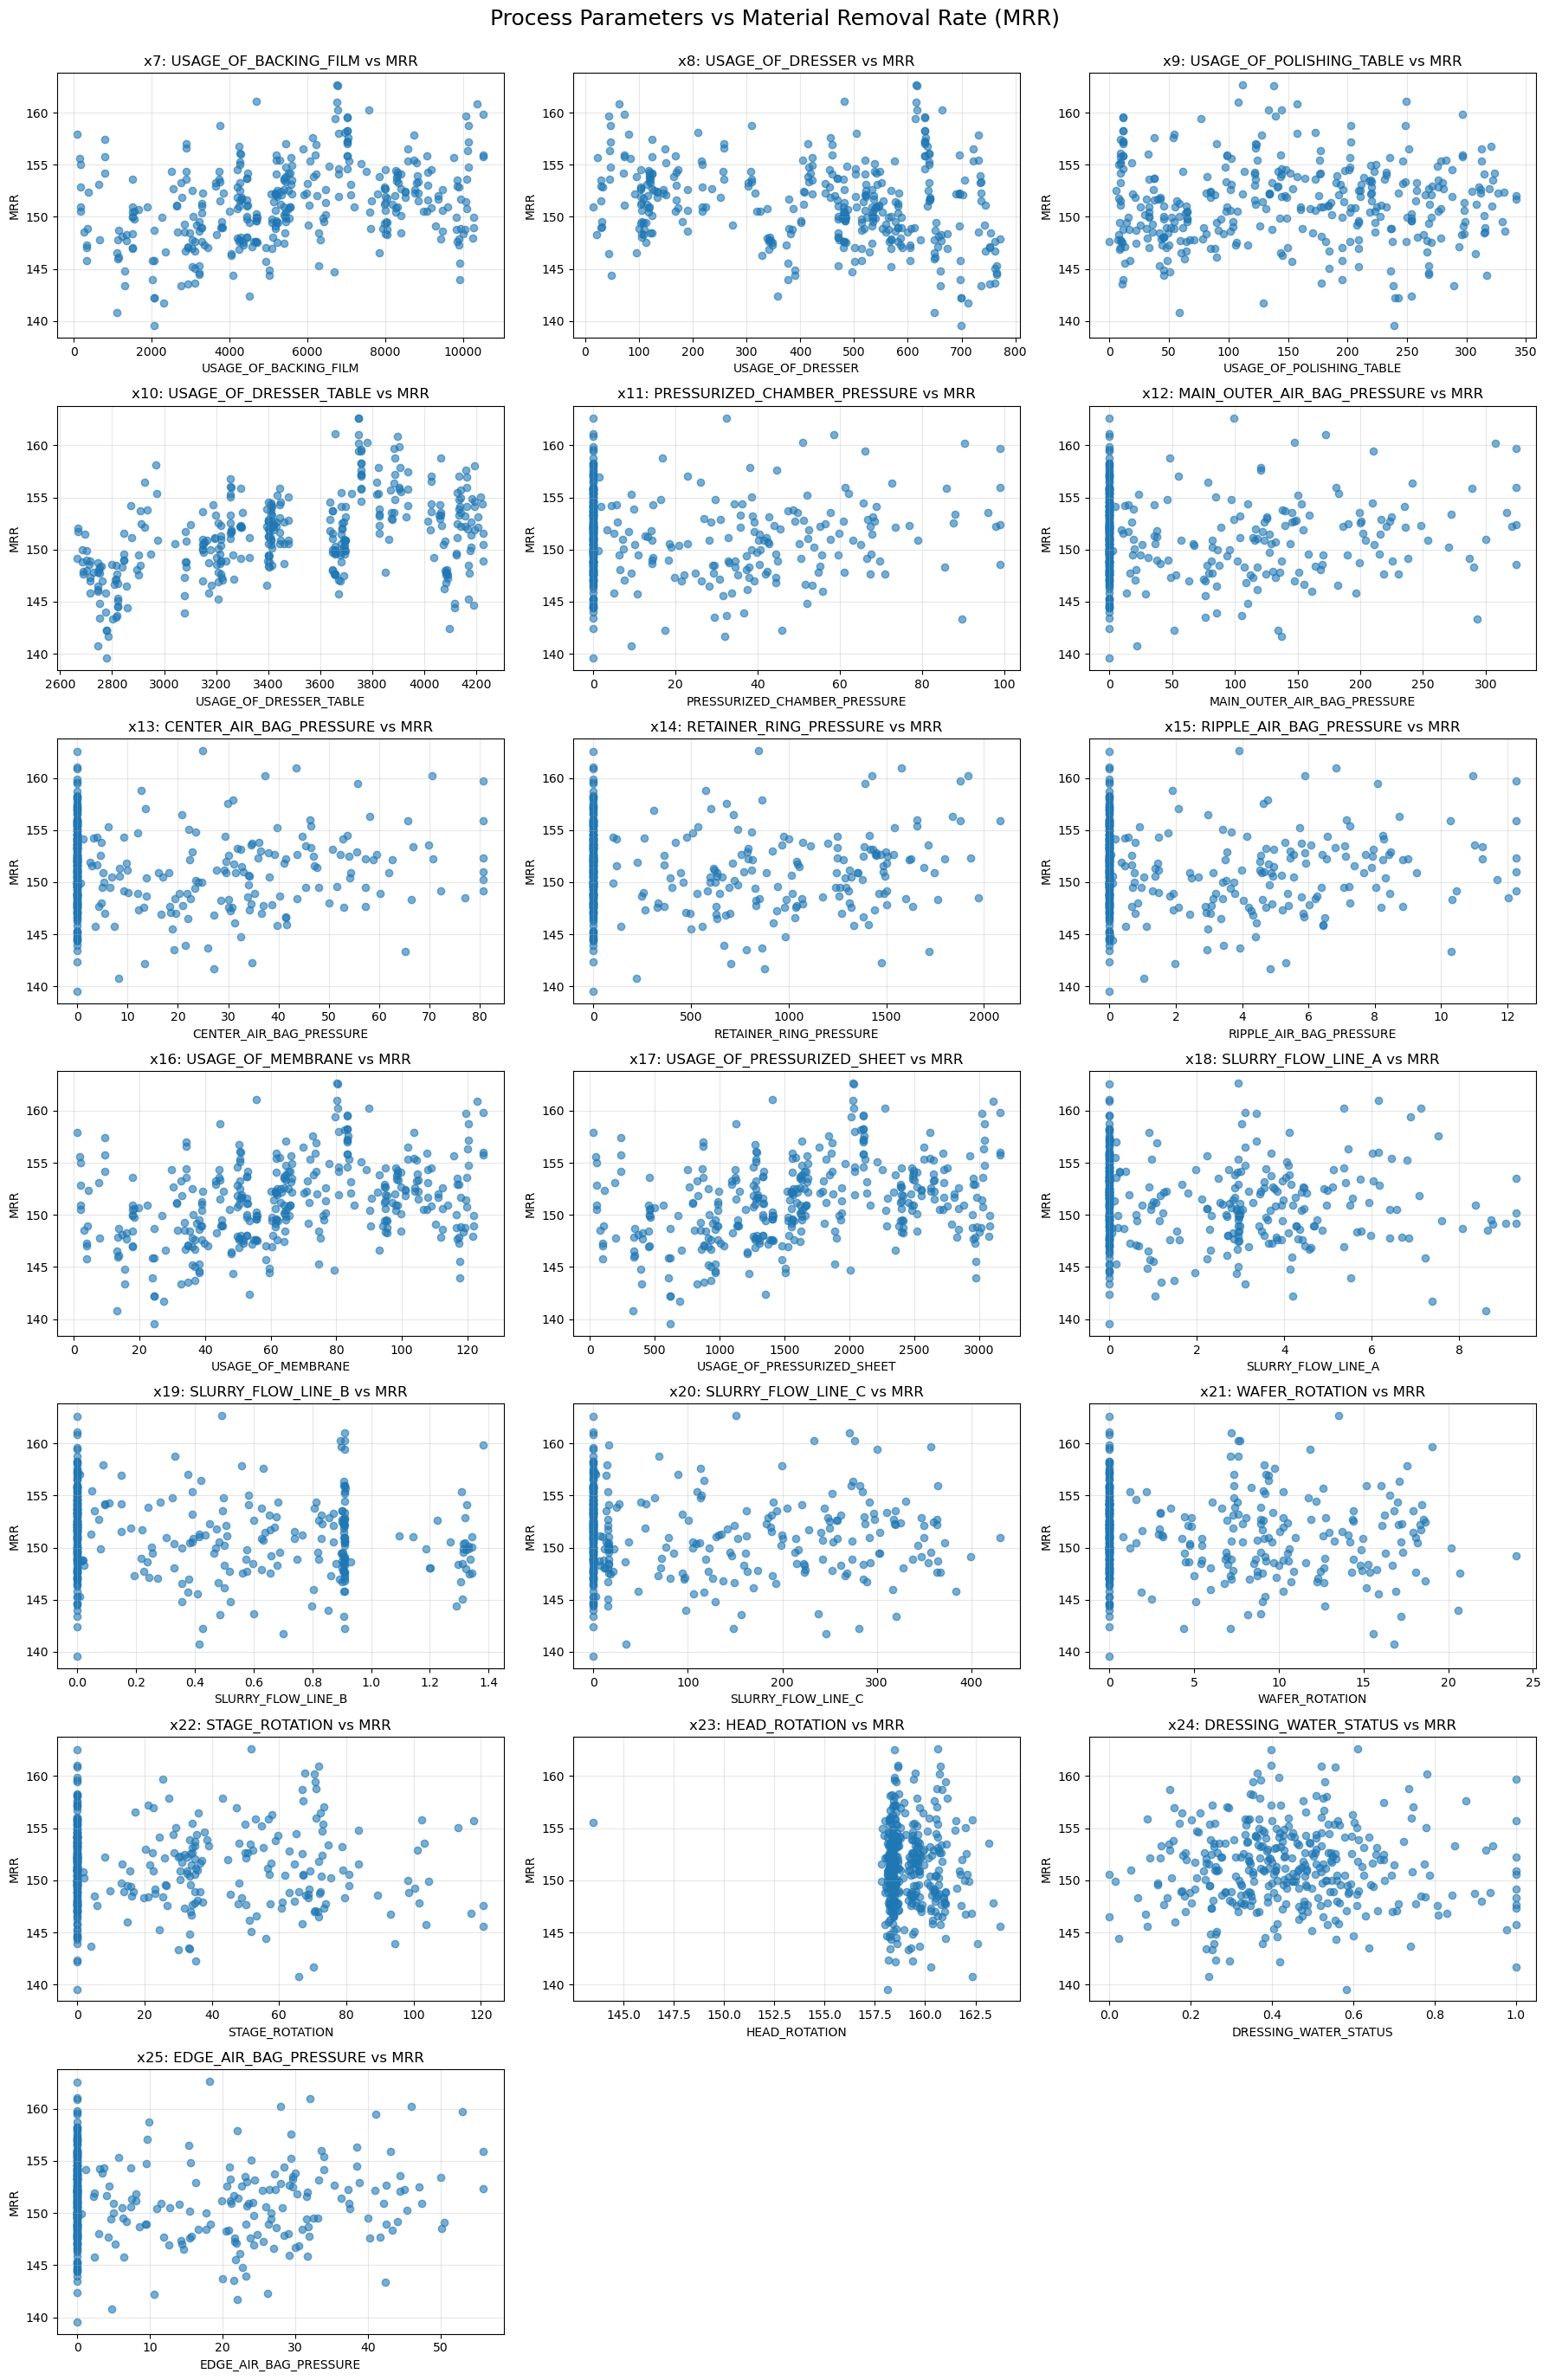

In [49]:
import matplotlib.pyplot as plt

# 7 x 3 grid for 19 scatter plots
fig, axes = plt.subplots(7, 3, figsize=(18, 28))

# Flatten axes for easy indexing
axes = axes.flatten()

# Plot x7-x25 against MRR
for i in range(19):

    axes[i].scatter(
        cleaned_data[:, i + 6],
        cleaned_data[:, 25],
        alpha=0.6
    )

    axes[i].set_xlabel(column_names[i + 6])
    axes[i].set_ylabel("MRR")

    axes[i].set_title(
        f"x{i+7}: {column_names[i+6]} vs MRR"
    )

    axes[i].grid(True, alpha=0.3)

# Hiding the two unused subplot spaces
for i in range(19, 21):
    axes[i].axis("off")

# Overall title
fig.suptitle(
    "Process Parameters vs Material Removal Rate (MRR)",
    fontsize=18
)


plt.tight_layout(rect=[0, 0, 1, 0.98])


plt.savefig(
    "scatter_plots_process_parameters_vs_MRR.png",
    dpi=300,
    bbox_inches="tight"
)

# Display figure
plt.show()

In [50]:
import os

print(os.getcwd())
print(os.path.abspath("scatter_plots_process_parameters_vs_MRR.png"))

C:\Users\emeni\Jupyter_WorkBook
C:\Users\emeni\Jupyter_WorkBook\scatter_plots_process_parameters_vs_MRR.png
